## Sanity check does cultured alex settling distrib look the same as bloom after IPW corrections


## Asside to calcuate this for just Alex Corrections 

Ends with saving data to json that can be loaded

In [2]:
## Create Corrected Arrivals for Nauset

### combine and filter dataframes


from pathlib import Path
import pandas as pd

def combine_csvs_with_filename(directory):
    """
    Combine all CSV files in a directory into one DataFrame.
    Adds a 'FileName' column containing the source filename.
    """
    dfs = []

    for file in Path(directory).glob("*.csv"):
        df = pd.read_csv(file)
        df["FileName"] = file.name
        dfs.append(df)

    if not dfs:
        return pd.DataFrame()

    return pd.concat(dfs, ignore_index=True)


def filter_class(class_name,master_df, alpha):
    """
    Return rows where any column beginning with 'class_name'
    has a value greater than alpha.
    """
    class_cols = [
        col for col in master_df.columns
        if str(col).startswith(class_name)
    ]

    if not class_cols:
        raise ValueError(f"No {class_name} columns found in master_df.")

    mask = (
        master_df[class_cols]
        .apply(lambda col: col > alpha)
        .any(axis=1)
    )

    return master_df.loc[mask].copy()


In [3]:
master_df = combine_csvs_with_filename("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/nauset/20240429/nauset/merged")
alexfilt_df = filter_class("Alexandrium", master_df, alpha=0.9)
masterROI_df = master_df[master_df['RoiType'] != 0]

print(f"Master dataframe shape: {master_df.shape}")
print(f"Master ROI dataframe shape: {masterROI_df.shape}")
print(f"Filtered DataFrame shape: {alexfilt_df.shape}")

Master dataframe shape: (491955, 151)
Master ROI dataframe shape: (491775, 151)
Filtered DataFrame shape: (105694, 151)


In [4]:
import numpy as np

def compute_ipw_weights(runtimes, inhibit_df, min_capture_prob=0.05):
    """
    Compute inverse probability weights for a list of particle runtimes.

    Parameters
    ----------
    runtimes : array-like
        Particle arrival times.

    inhibit_df : DataFrame
        Must contain columns:
            - t_start
            - t_end
            - p_inhib

    Returns
    -------
    weights : np.ndarray
        Inverse probability weights for each runtime.
    """

    inhibit_df = inhibit_df.sort_values("t_start")

    t_start = inhibit_df["t_start"].to_numpy()
    t_end = inhibit_df["t_end"].to_numpy()
    p_inhibit = inhibit_df["p_inhib"].to_numpy()

    runtimes = np.asarray(runtimes)

    idx = np.searchsorted(t_start, runtimes, side="right") - 1

    p = np.zeros(len(runtimes))

    valid = (
        (idx >= 0) &
        (idx < len(t_start)) &
        (runtimes < t_end[idx])
    )

    p[valid] = p_inhibit[idx[valid]]

    p_capture = np.clip(1 - p, min_capture_prob, 1)

    weights = 1 / p_capture

    return weights

In [7]:
runtime_array = alexfilt_df['RunTime'].to_numpy()
runtime_array[:5]

array([ 2.4006033 ,  7.80306424,  9.22892795,  9.80354818, 11.66676432])

In [9]:
pw_df = pd.read_csv("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/nauset/20240429/20240429nauset_pw_df.csv")
pw_df.head()

,t_start,t_end,active,inhib,p_inhib
0,0.000000,1.495734,61,0,0.000000
1,1.495734,1.576445,61,1,0.016393
2,1.576445,1.684813,61,0,0.000000
3,1.684813,1.700605,61,1,0.016393
4,1.700605,1.763859,61,2,0.032787


In [ ]:
weights = compute_ipw_weights(runtime_array, pw_df, min_capture_prob=0.001)


NameError: name 'plt' is not defined

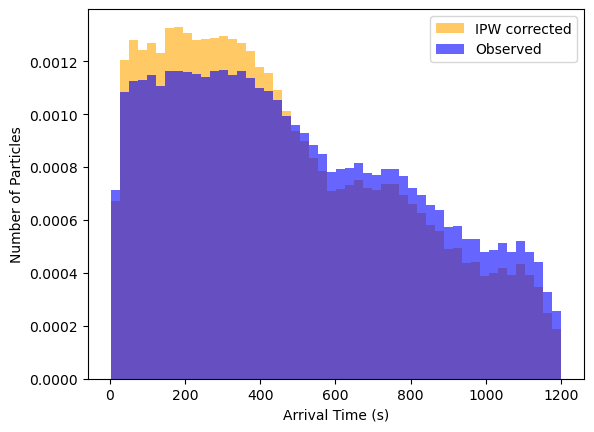

In [13]:
import matplotlib.pyplot as plt
plt.hist(runtime_array,
         bins=50,
         weights=weights,
         density=True,
         color='orange',
         alpha=0.6,
         label="IPW corrected")
plt.hist(runtime_array, 
         bins=50, 
         alpha=0.6,
         density=True,
         color='blue',
         label="Observed")
plt.xlabel("Arrival Time (s)")
plt.ylabel("Number of Particles")

plt.legend()

In [14]:
np.save("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/nauset/20240429/20240429nauset_weights.npy", weights)

In [15]:
import json
import numpy as np
import pandas as pd
from pathlib import Path


def build_corrected_arrival_list(
    df: pd.DataFrame,
    time_col: str = "arrival_time",
    weight_col: str = "weight",
    seed: int | None = None,
    keep_observed_once: bool = True,
    inhibit_time: float = 0.08
) -> dict:
    """
    Build a corrected pseudo-population of arrival times from IPW weights.

    Each observed arrival is expanded into an integer number of pseudo-arrivals.
    The number of copies is sampled from a Poisson distribution with mean equal
    to the IPW weight. This preserves randomness while creating a corrected list
    you can later resample from.

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain arrival times and weights.
    time_col : str
        Column name for arrival times.
    weight_col : str
        Column name for IPW weights.
    seed : int or None
        Random seed for reproducibility.
    keep_observed_once : bool
        If True, each observed arrival contributes at least one copy before
        adding Poisson extra copies. If False, total copies are drawn directly
        from Poisson(weight).
    inhibit_time : float
        Maximum time window to jitter the pseudo-arrivals. Each pseudo-arrival
        is sampled uniformly from [arrival_time, arrival_time + inhibit_time].

    Returns
    -------
    dict
        JSON-serializable object with corrected arrival times and metadata.
    """
    rng = np.random.default_rng(seed)

    work = df[[time_col, weight_col]].dropna().copy()
    work[weight_col] = work[weight_col].astype(float)
    work = work[work[weight_col] > 0]

    corrected_times = []
    source_map = []

    for idx, row in work.reset_index(drop=True).iterrows():
        t = float(row[time_col])
        w = float(row[weight_col])

        if keep_observed_once:
            n_copies = 1 + rng.poisson(max(w - 1.0, 0.0)) ## This is the issue I should maybe sample from poisson distrib with sd of inhibit_time/2
        else:
            n_copies = rng.poisson(w)

        for _ in range(n_copies):
            jittered_t = rng.uniform(t, t + inhibit_time) ## this now samples n number of times from uniform distrib from t, t+inhibit_time logic is that is when we are missing particles in that time frame
            corrected_times.append(jittered_t)
            source_map.append(int(idx))

    corrected_times = sorted(corrected_times)

    return {
        "method": "ipw_poisson_expansion",
        "seed": seed,
        "keep_observed_once": keep_observed_once,
        "n_observed": int(len(work)),
        "n_corrected": int(len(corrected_times)),
        "arrival_times": corrected_times,
        "source_index": source_map,
    }


def save_corrected_arrivals(result: dict, output_path: str | Path) -> None:
    output_path = Path(output_path)
    with output_path.open("w") as f:
        json.dump(result, f, indent=2)

In [16]:
working_df = pd.DataFrame({"RunTime": runtime_array, "IPW": weights})

In [17]:
result = build_corrected_arrival_list(
    working_df,
    time_col="RunTime",
    weight_col="IPW",
    seed=42,
    keep_observed_once=True,
    inhibit_time=0.08
)

arrival_times = result["arrival_times"]

print(f"Number of unique arrival times: {len(np.unique(arrival_times))}")
print(f"Number of total arrival times: {len(arrival_times)}")



Number of unique arrival times: 223712
Number of total arrival times: 223712


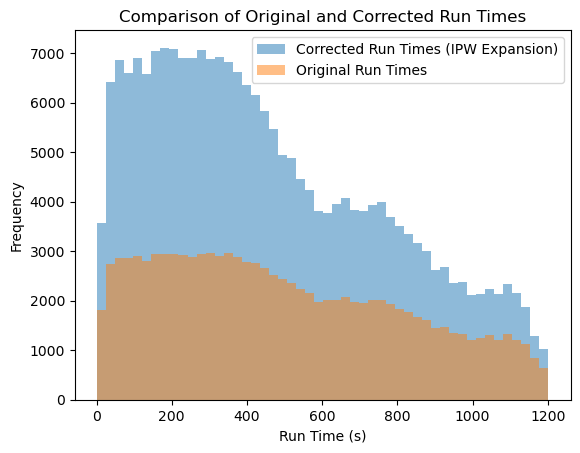

In [18]:


plt.hist(result["arrival_times"], bins=50, alpha=0.5, label="Corrected Run Times (IPW Expansion)")
plt.hist(runtime_array, bins=50, alpha=0.5, label="Original Run Times")
plt.xlabel("Run Time (s)")
plt.ylabel("Frequency")
plt.title("Comparison of Original and Corrected Run Times")
plt.legend()

In [19]:
def save_corrected_arrivals(result: dict, output_path: str | Path) -> None:
    output_path = Path(output_path)
    with output_path.open("w") as f:
        json.dump(result, f, indent=2)

save_corrected_arrivals(result, "/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/nauset/20240429/20240429NausetCorrectedArrivals.json")

## Comparing Distributions

In [20]:
## Load Dfs

## Build Cultured alex this is just redoing existing work
import pandas as pd

Culture_corrected = pd.read_json("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/dilExp/Alex/AlexHighV_corrected_arrivals.json")
Nauset_corrected = pd.read_json("/Users/michaelstaiger/Desktop/gitRepos/IFCBParticleSize/EmpyricalAnalysis/IFCBData/nauset/20240429/20240429NausetCorrectedArrivals.json")



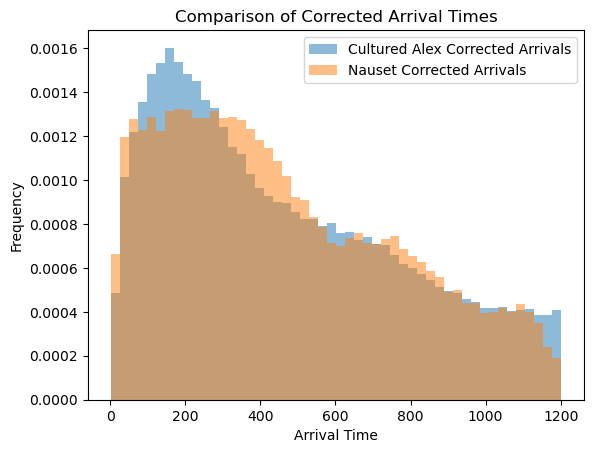

In [24]:
plt.hist(Culture_corrected["arrival_times"], bins=50, alpha=0.5, label="Cultured Alex Corrected Arrivals", density=True)
plt.hist(Nauset_corrected["arrival_times"], bins=50, alpha=0.5, label="Nauset Corrected Arrivals", density=True)
plt.xlabel("Arrival Time")
plt.ylabel("Frequency")
plt.title("Comparison of Corrected Arrival Times")
plt.legend()
plt.show()

In [28]:
from scipy.stats import wasserstein_distance

culture_arrival_times = np.asarray(Culture_corrected["arrival_times"])
nauset_arrival_times = np.asarray(Nauset_corrected["arrival_times"])
emd = wasserstein_distance(culture_arrival_times, nauset_arrival_times)
print(f"Wasserstein distance (Earth Mover's Distance) between Cultured Alex and Nauset corrected arrivals: {emd}")

Wasserstein distance (Earth Mover's Distance) between Cultured Alex and Nauset corrected arrivals: 11.720512466814336


In [35]:
## Permute to get P value


rng = np.random.default_rng(42)
pooled = np.concatenate((culture_arrival_times, nauset_arrival_times))

n_a = len(culture_arrival_times)
n_permutations = 1000
null_emd = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled = rng.permutation(pooled)

    randomized_a = shuffled[:n_a]
    randomized_b = shuffled[n_a:]

    null_emd[i] = wasserstein_distance(randomized_a, randomized_b)

p_value = (np.sum(null_emd >= emd) + 1) / (n_permutations + 1)

print("Observed EMD:", emd)
print("Permutation p-value:", p_value)

Observed EMD: 11.720512466814336
Permutation p-value: 0.000999000999000999


In [33]:
print("Observed EMD:", emd)
print("Permutation p-value:", p_value)

Observed EMD: 11.720512466814336


NameError: name 'p_value' is not defined

In [37]:
bootstrap_emd = np.empty(n_permutations)
a = culture_arrival_times
b = nauset_arrival_times

for i in range(n_permutations):
    resampled_a = rng.choice(a, size=len(a), replace=True)
    resampled_b = rng.choice(b, size=len(b), replace=True)

    bootstrap_emd[i] = wasserstein_distance(
        resampled_a,
        resampled_b
    )

ci_low, ci_high = np.percentile(bootstrap_emd, [2.5, 97.5])

print("95% bootstrap CI:", ci_low, ci_high)

95% bootstrap CI: 10.990350302878774 12.41827376204906
